# Práctica 5 — PCA y dataset final

Se toma como base los archivos que generan los notebooks de **normalización** y **Pearson**.

### 1. Importar bibliotecas y encontrar el archivo

Se usa  `pandas` para los datos, `numpy` para calculos, `matplotlib` para las graficas y `PCA`.

In [24]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from IPython.display import display

# Se busca el proyecto 
proyecto = Path.cwd()
if proyecto.name == "notebooks":
    proyecto = proyecto.parent
if (proyecto / "proyecto").is_dir():
    proyecto = proyecto / "proyecto"

ruta_datos = proyecto / "data" / "data-processed"
ruta_figuras = proyecto / "notebooks" / "figures"
ruta_figuras.mkdir(parents=True, exist_ok=True)

archivo = ruta_datos / "household_power_consumption_zscore.csv"
if not archivo.is_file():
    raise FileNotFoundError("No se encontro el CSV Z-score. Ejecuta primero normalizacion.ipynb")

print("Archivo encontrado:", archivo)

Archivo encontrado: /home/oscarpago/Semestre 7/Almacenes/Practica5/Practica5_Norma_PCA/proyecto/data/data-processed/household_power_consumption_zscore.csv


### 2. Cargar los datos estandarizados

Este es el CSV que generó la Persona 2 con **Z-score**. La columna `Datetime` sirve para ordenar y separar los periodos, pero **no entra al PCA**.

In [25]:
df = pd.read_csv(archivo, sep=";", parse_dates=["Datetime"])

print("Filas:", len(df))
print("Columnas:", list(df.columns))
print("Valores faltantes:", df.isna().sum().sum())
display(df.head())

Filas: 2049280
Columnas: ['Datetime', 'Global_active_power', 'Global_reactive_power', 'Voltage', 'Global_intensity', 'Sub_metering_1', 'Sub_metering_2', 'Sub_metering_3']
Valores faltantes: 0


,Datetime,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3
0,2006-12-16 17:24:00,2.857736,2.641943,-1.749768,2.994735,-0.184404,-0.059039,1.289969
1,2006-12-16 17:25:00,3.907056,2.802641,-2.114446,3.998119,-0.184404,-0.059039,1.170164
2,2006-12-16 17:26:00,3.919897,3.356158,-2.216918,3.998119,-0.184404,0.107234,1.289969
3,2006-12-16 17:27:00,3.932739,3.391869,-2.081294,3.998119,-0.184404,-0.059039,1.289969
4,2006-12-16 17:28:00,2.353255,3.623988,-1.496603,2.427606,-0.184404,-0.059039,1.289969


### 3. Conservar las variables que dejó Pearson

En `pearson.ipynb` se encontró una correlación cercana a 0.999 entre `Global_active_power` y `Global_intensity`. Con un umbral de `0.90` se decidio eliminar `Global_intensity` y mantener seis variables.

In [26]:
variables = [
    "Global_active_power",
    "Global_reactive_power",
    "Voltage",
    "Sub_metering_1",
    "Sub_metering_2",
    "Sub_metering_3"
]

print("Numero de variables para PCA: ", len(variables))
print("Variables:", variables)

Numero de variables para PCA:  6
Variables: ['Global_active_power', 'Global_reactive_power', 'Voltage', 'Sub_metering_1', 'Sub_metering_2', 'Sub_metering_3']


### 4. Separar entrenamiento y revisar Z-score

Al igual que en los notebooks anteriores, los datos anteriores al 1 de enero de 2010 son de entrenamiento. Los de 2010 son de prueba.

El PCA se ajusta solo con entrenamiento para no usar información futura. Comprobamos también que sus medias sean cercanas a 0 y sus desviaciones estandar cercanas a 1.

In [27]:
fecha_corte = pd.Timestamp("2010-01-01")

entrenamiento = df.loc[df["Datetime"] < fecha_corte, variables]
prueba = df.loc[df["Datetime"] >= fecha_corte, variables]

print("Filas de entrenamiento:", len(entrenamiento))
print("Filas de prueba:", len(prueba))

revision = pd.DataFrame({
    "media": entrenamiento.mean(),
    "desviacion_estandar": entrenamiento.std(ddof=0)
})
display(revision.round(4))

Filas de entrenamiento: 1591886
Filas de prueba: 457394


,media,desviacion_estandar
Global_active_power,-0.0,1.0
Global_reactive_power,-0.0,1.0
Voltage,-0.0,1.0
Sub_metering_1,0.0,1.0
Sub_metering_2,0.0,1.0
Sub_metering_3,0.0,1.0


### 5. Aplicar PCA

Utilizamos `PCA()` y con `fit()` calculamos las componentes usando solo el entrenamiento. Al principio calculamos las seis componentes para poder comparar la varianza que explica cada una

In [28]:
pca = PCA()
pca.fit(entrenamiento)

print("PCA ajustado con", pca.n_features_in_, "variables")
print("Componentes calculadas:", pca.n_components_)

PCA ajustado con 6 variables
Componentes calculadas: 6


### 6. Varianza explicada y elección de componentes

La varianza explicada nos dice cuanto de la variabilidad de los datos representa cada componente. La acumulada suma los porcentajes de las primeras componentes.

Como criterio decidimos conservar al menos el 95 % de la varianza del entrenamiento.

In [29]:
tabla_varianza = pd.DataFrame({
    "Componente": ["PC1", "PC2", "PC3", "PC4", "PC5", "PC6"],
    "Varianza explicada": pca.explained_variance_ratio_
})

tabla_varianza["Varianza acumulada"] = tabla_varianza["Varianza explicada"].cumsum()

#Se cuentan cuantas componentes hacen falta para llegar al 95%
numero_componentes = 0
for valor in tabla_varianza["Varianza acumulada"]:
    numero_componentes += 1
    if valor >= 0.95:
        break

print("Componentes que conservaremos:", numero_componentes)
print("Varianza acumulada:", round(tabla_varianza.iloc[numero_componentes - 1]["Varianza acumulada"] * 100, 2), "%")
display((tabla_varianza.set_index("Componente") * 100).round(2))

Componentes que conservaremos: 5
Varianza acumulada: 97.23 %


,Varianza explicada,Varianza acumulada
Componente,,
PC1,38.70,38.70
PC2,16.47,55.16
PC3,15.59,70.75
PC4,13.87,84.63
PC5,12.61,97.23
PC6,2.77,100.00


### 7. Scree plot (gráfica de varianza)

Las barras muestran la varianza explicada por cada PC. La línea muestra el porcentaje acumulado. La línea horizontal indica nuestro objetivo del 95 %.

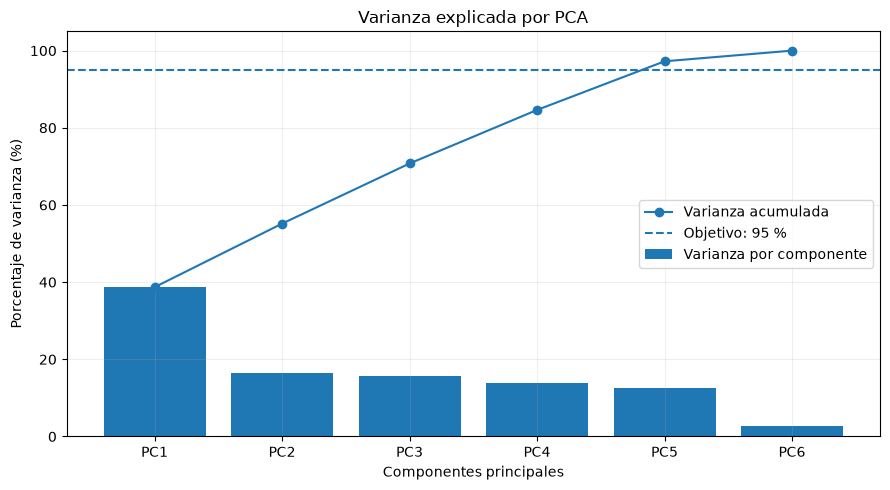

In [30]:
plt.figure(figsize=(9, 5))
plt.bar(tabla_varianza["Componente"], tabla_varianza["Varianza explicada"] * 100,
        label="Varianza por componente")
plt.plot(tabla_varianza["Componente"], tabla_varianza["Varianza acumulada"] * 100,
         marker="o", label="Varianza acumulada")
plt.axhline(95, linestyle="--", label="Objetivo: 95 %")
plt.xlabel("Componentes principales")
plt.ylabel("Porcentaje de varianza (%)")
plt.title("Varianza explicada por PCA")
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.savefig(ruta_figuras / "pca_scree_plot.png")
plt.show()

### 8. Loadings: ¿qué variables influyen más?

Los **loadings** nos ayudan a interpretar cada PC. Aquí los calculamos como la correlación entre cada variable y cada componente. Un valor cercano a 1 o -1 indica una asociación fuerte.

Nos fijamos en el **valor absoluto** para encontrar las variables con mayor influencia, pero también miramos su signo para interpretarlas.

In [31]:
#Primero obtenemos la desviación estandar de cada variable
desviaciones = entrenamiento.std(ddof=1).values

# Calculamos los loadings de cada componente
tabla_loadings = pd.DataFrame(index=variables)
for i in range(len(variables)):
    cargas = pca.components_[i] * np.sqrt(pca.explained_variance_[i])
    tabla_loadings["PC" + str(i + 1)] = cargas / desviaciones

print("Loadings de las componentes seleccionadas: ")
display(tabla_loadings.iloc[:, :numero_componentes].round(3))

for pc in tabla_loadings.columns[:numero_componentes]:
    print("Variables mas relacionadas con", pc)
    print(tabla_loadings[pc].abs().sort_values(ascending=False).head(3).round(3))

Loadings de las componentes seleccionadas: 


,PC1,PC2,PC3,PC4,PC5
Global_active_power,0.926,-0.064,-0.025,-0.058,0.200
Global_reactive_power,0.374,0.687,0.242,0.572,-0.033
Voltage,-0.592,0.189,0.059,-0.020,0.781
Sub_metering_1,0.541,0.007,0.706,-0.426,0.097
Sub_metering_2,0.493,0.482,-0.580,-0.409,0.075
Sub_metering_3,0.662,-0.494,-0.193,0.391,0.302


Variables mas relacionadas con PC1
Global_active_power    0.926
Sub_metering_3         0.662
Voltage                0.592
Name: PC1, dtype: float64
Variables mas relacionadas con PC2
Global_reactive_power    0.687
Sub_metering_3           0.494
Sub_metering_2           0.482
Name: PC2, dtype: float64
Variables mas relacionadas con PC3
Sub_metering_1           0.706
Sub_metering_2           0.580
Global_reactive_power    0.242
Name: PC3, dtype: float64
Variables mas relacionadas con PC4
Global_reactive_power    0.572
Sub_metering_1           0.426
Sub_metering_2           0.409
Name: PC4, dtype: float64
Variables mas relacionadas con PC5
Voltage                0.781
Sub_metering_3         0.302
Global_active_power    0.200
Name: PC5, dtype: float64


### 9. Proyección de los datos en dos dimensiones

Usamos `transform()` para representar las observaciones con PC1 y PC2.
Tomamos solo 10000 filas para la grafica para no dibujar los 2 millones de puntos

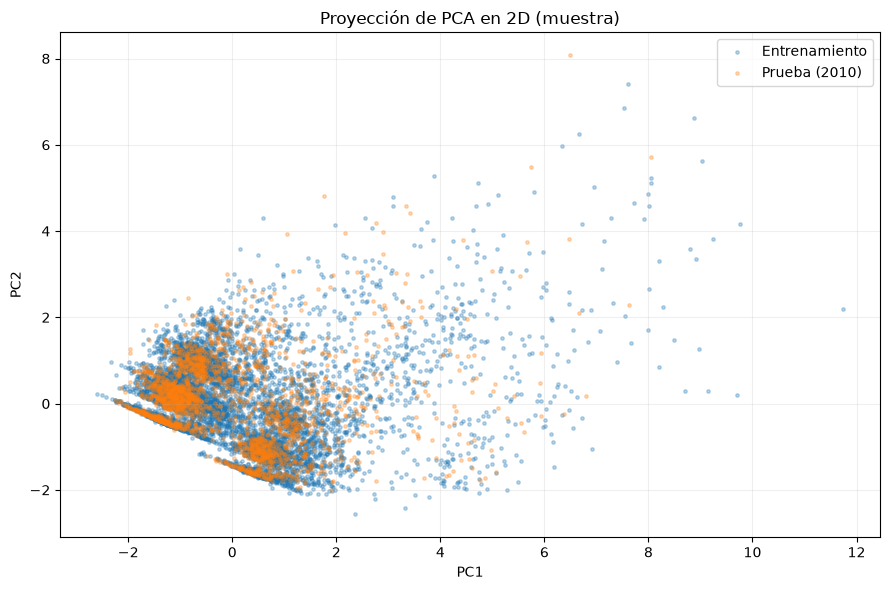

In [32]:
muestra = df.sample(n=min(10000, len(df)), random_state=42).copy()
puntos = pca.transform(muestra[variables])

muestra["PC1"] = puntos[:, 0]
muestra["PC2"] = puntos[:, 1]

muestra_train = muestra[muestra["Datetime"] < fecha_corte]
muestra_test = muestra[muestra["Datetime"] >= fecha_corte]

plt.figure(figsize=(9, 6))
plt.scatter(muestra_train["PC1"], muestra_train["PC2"],
            s=6, alpha=0.3, label="Entrenamiento")
plt.scatter(muestra_test["PC1"], muestra_test["PC2"],
            s=6, alpha=0.3, label="Prueba (2010)")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("Proyección de PCA en 2D (muestra)")
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.savefig(ruta_figuras / "pca_proyeccion_2d.png")
plt.show()

### 10. Crear y guardar el dataset final

Ahora transformamos todas las filas utilizando el PCA que aprendio del entrenamiento. Guardamos la fecha, las seis variables normalizadas y las componentes seleccionadas

In [33]:
#Transforma todas las filas
datos_pca = pca.transform(df[variables])

df_final = df[["Datetime"] + variables].copy()

for i in range(numero_componentes):
    df_final["PC" + str(i + 1)] = datos_pca[:, i]

# Guarda los resultados sin modificar los CSV anteriores
ruta_final = ruta_datos / "household_power_consumption_final.csv"
df_final.to_csv(ruta_final, sep=";", index=False)
tabla_varianza.to_csv(ruta_datos / "pca_varianza_explicada.csv", sep=";", index=False)
tabla_loadings.to_csv(ruta_datos / "pca_loadings.csv", sep=";")

print("Dataset final guardado en: ", ruta_final)
print("Tamaño final:", df_final.shape)
display(df_final.head())

Dataset final guardado en:  /home/oscarpago/Semestre 7/Almacenes/Practica5/Practica5_Norma_PCA/proyecto/data/data-processed/household_power_consumption_final.csv
Tamaño final: (2049280, 12)


,Datetime,Global_active_power,Global_reactive_power,Voltage,Sub_metering_1,Sub_metering_2,Sub_metering_3,PC1,PC2,PC3,PC4,PC5
0,2006-12-16 17:24:00,2.857736,2.641943,-1.749768,-0.184404,-0.059039,1.289969,3.540938,0.637164,0.122822,2.181607,-0.590306
1,2006-12-16 17:25:00,3.907056,2.802641,-2.114446,-0.184404,-0.059039,1.170164,4.307691,0.670516,0.137033,2.173029,-0.723779
2,2006-12-16 17:26:00,3.919897,3.356158,-2.216918,-0.184404,0.107234,1.289969,4.597088,1.053795,0.145279,2.498652,-0.777618
3,2006-12-16 17:27:00,3.932739,3.391869,-2.081294,-0.184404,-0.059039,1.289969,4.507127,1.022862,0.261968,2.591692,-0.668641
4,2006-12-16 17:28:00,2.353255,3.623988,-1.496603,-0.184404,-0.059039,1.289969,3.377113,1.396751,0.397273,2.823908,-0.515922


### 11. Revisiones finales

In [34]:
print("Filas originales:", len(df))
print("Filas finales:", len(df_final))
print("Esta Global_intensity?:", "Global_intensity" in df_final.columns)
print("Valores faltantes en el dataset final: ", df_final.isna().sum().sum())
print("Columnas : ", list(df_final.columns))

Filas originales: 2049280
Filas finales: 2049280
Esta Global_intensity?: False
Valores faltantes en el dataset final:  0
Columnas :  ['Datetime', 'Global_active_power', 'Global_reactive_power', 'Voltage', 'Sub_metering_1', 'Sub_metering_2', 'Sub_metering_3', 'PC1', 'PC2', 'PC3', 'PC4', 'PC5']
